# Statistical Analysis — Parametric / Non-parametric

This is an analysis for random number generator + using parametric / non-parametric statistical analysis.

**Data:** Synthetic independent observations in five experimental groups. Fixed random seed for reproducibility.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

rng = np.random.default_rng(42)

n = 30

groups = {
    # Normally distributed
    "Control": rng.normal(loc=10, scale=3, size=n), # mean=10, std=3
    "Group A": rng.normal(loc=10, scale=3, size=n), # mean=10, std=3
    "Group B": rng.normal(loc=13, scale=4, size=n), # mean=13, std=4
    "Group C": rng.normal(loc=19, scale=3, size=n), # mean=19, std=3
    "Group D": rng.normal(loc=17, scale=6, size=n) # mean=17, std=6
}

df = pd.DataFrame(groups)

display(df.head())
display(df.describe()) # descriptive statistics for each group

,Control,Group A,Group B,Group C,Group D
0,10.914151,16.424943,6.268521,20.996155,10.859015
1,6.880048,8.780755,11.660460,18.704544,18.075654
2,12.251354,8.463272,13.651012,17.730105,18.319980
3,12.821694,7.558682,15.344889,18.760845,25.155125
4,4.146894,11.847938,15.844906,13.937997,22.010667


,Control,Group A,Group B,Group C,Group D
count,30.000000,30.000000,30.000000,30.000000,30.000000
mean,10.050442,10.341270,12.593617,18.188252,16.931963
std,2.330247,2.414149,2.747950,2.545703,6.661655
min,4.146894,5.628533,6.268521,13.818039,4.207722
25%,8.772162,8.494674,11.185692,16.220251,11.610997
50%,10.290807,10.503062,12.642380,18.132417,17.048773
75%,11.548328,11.937300,14.941664,19.709412,20.479793
max,13.667624,16.424943,16.431904,23.805337,34.483175


## Visualization

**Purpose:** Inspect group distributions before statistical testing.

- **Boxplot:** Median, interquartile range, and spread.
- **Density plot:** Estimated distribution shape.

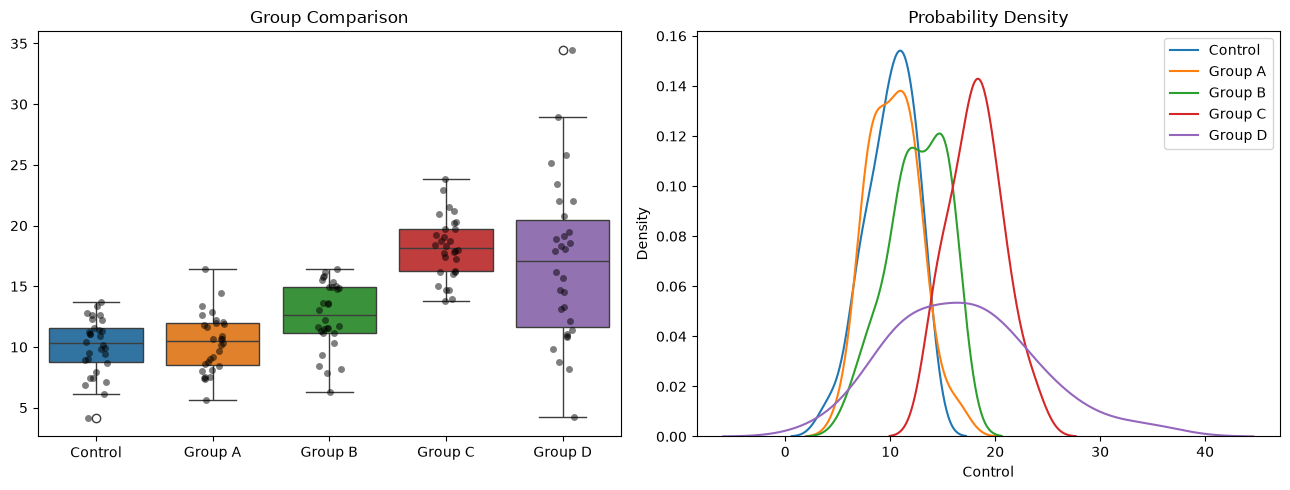

In [2]:
# Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5)) # fig. w/ 1 row, 2 columns, size 13x5 inches

sns.boxplot(data=df, ax=axes[0]) # boxplot
sns.stripplot(data=df, color="black", alpha=0.5, ax=axes[0]) # stripplot overlay
axes[0].set_title("Group Comparison") # title [0]

for column in df.columns:
    sns.kdeplot(df[column], label=column, ax=axes[1]) # kdeplot for each group

axes[1].legend()
axes[1].set_title("Probability Density")

plt.tight_layout()
plt.show()

## Normality Test (Shapiro)

The Shapiro test evaluates whether data significantly deviate from a normal distribution.

- **H₀:** Data follow a normal distribution.
- **H₁:** Data do not follow a normal distribution.

**Interpretation:**
- p < 0.05: Reject H₀.
- p ≥ 0.05: Fail to reject H₀.

- **W (test statistic):** Measures agreement with a normal distribution. W ≈ 1 indicates better agreement.
- **p (p-value):** Probability of obtaining a test statistic this extreme or more extreme, assuming normality.

In [3]:
# Shapiro test
for name in df.columns:
    W, p = stats.shapiro(df[name])
    print(f"{name}: W={W:.3f}, p={p:.4f}")

Control: W=0.965, p=0.4161
Group A: W=0.977, p=0.7444
Group B: W=0.940, p=0.0928
Group C: W=0.981, p=0.8539
Group D: W=0.977, p=0.7474


**Interpretation:** A p-value ≥ 0.05 does not prove normality; it means the test did not detect a significant departure.

## Group Comparisons

**Welch's ANOVA (Parametric)**
- H₀: All group means are equal.
- F: Between-group relative to within-group variation.
- p < 0.05: Evidence that at least one group mean differs.

**Kruskal–Wallis (Non-parametric)**
- H₀: All group distributions are equal.
- H: Rank-based test statistic.
- p < 0.05: Evidence of a distributional difference.

In [4]:
# Parametric: Welch's ANOVA (does not assume equal group variances)
# Requires SciPy >= 1.15
F, p_anova = stats.f_oneway(*groups.values(), equal_var=False)

# Non-parametric: Kruskal–Wallis
H, p_kw = stats.kruskal(*groups.values())

print(f"Welch ANOVA: F={F:.3f}, p={p_anova:.5g}")
print(f"Kruskal–Wallis: H={H:.3f}, p={p_kw:.5g}")

Welch ANOVA: F=53.252, p=9.5707e-21
Kruskal–Wallis: H=74.525, p=2.5107e-15


Significant results indicate an overall group difference, but do not identify which groups differ. Very small p-values should not be interpreted as zero.

## Post-hoc Pairwise Comparisons

**Purpose:** Compare each treatment against Control.

**Parametric — Welch's t-test**
- H₀: The two population means are equal.
- t: Standardized difference between means.

**Non-parametric — Mann–Whitney U**
- H₀: Both groups have the same distribution.
- U: Rank-based test statistic.

**Interpretation:**
- p < 0.05: Significant difference before correction.
- p ≥ 0.05: No significant difference detected.

In [5]:
results = []

for name in list(groups.keys())[1:]:

    # Parametric
    t, p_t = stats.ttest_ind(
        groups["Control"], groups[name],
        equal_var=False
    )

    # Non-parametric
    U, p_u = stats.mannwhitneyu(
        groups["Control"], groups[name],
        alternative="two-sided"
    )

    results.append({
        "Comparison": f"Control vs {name}",
        "Welch p": p_t,
        "MWU p": p_u
    })

results_df = pd.DataFrame(results)
display(results_df)

,Comparison,Welch p,MWU p
0,Control vs Group A,6.367516e-01,8.418015e-01
1,Control vs Group B,2.880263e-04,4.981817e-04
2,Control vs Group C,1.199262e-18,3.019859e-11
3,Control vs Group D,5.289949e-06,1.018769e-05


## Benjamini–Hochberg Correction

**Purpose:** Control the false discovery rate (FDR) when performing multiple statistical tests.

- **p:** Original p-value.
- **Adjusted p:** P-value corrected for multiple comparisons.

**Interpretation:**
- Adjusted p < 0.05: Statistically significant.
- Adjusted p ≥ 0.05: Not statistically significant.

In [6]:
from statsmodels.stats.multitest import multipletests

# Parametric correction
results_df["Welch adjusted p"] = multipletests(
    results_df["Welch p"],
    method="fdr_bh"
)[1]

# Non-parametric correction
results_df["MWU adjusted p"] = multipletests(
    results_df["MWU p"],
    method="fdr_bh"
)[1]

results_df["Welch significant"] = (
    results_df["Welch adjusted p"] < 0.05
)

results_df["MWU significant"] = (
    results_df["MWU adjusted p"] < 0.05
)

display(results_df.round(5))

,Comparison,Welch p,MWU p,Welch adjusted p,MWU adjusted p,Welch significant,MWU significant
0,Control vs Group A,0.63675,0.84180,0.63675,0.84180,False,False
1,Control vs Group B,0.00029,0.00050,0.00038,0.00066,True,True
2,Control vs Group C,0.00000,0.00000,0.00000,0.00000,True,True
3,Control vs Group D,0.00001,0.00001,0.00001,0.00002,True,True


## Visualization

**Purpose:** Visualize the five experimental groups.

- **Boxplot:** Median and interquartile range (IQR).
- **Dots:** Individual measurements.
- **Stars:** Statistical significance compared with Control, using BH-adjusted Welch's t-test p-values.

Significance levels (adjusted p-values):
- \* p < 0.05
- \*\* p < 0.01
- \*\*\* p < 0.001
- \*\*\*\* p < 0.0001
- ns: Not significant

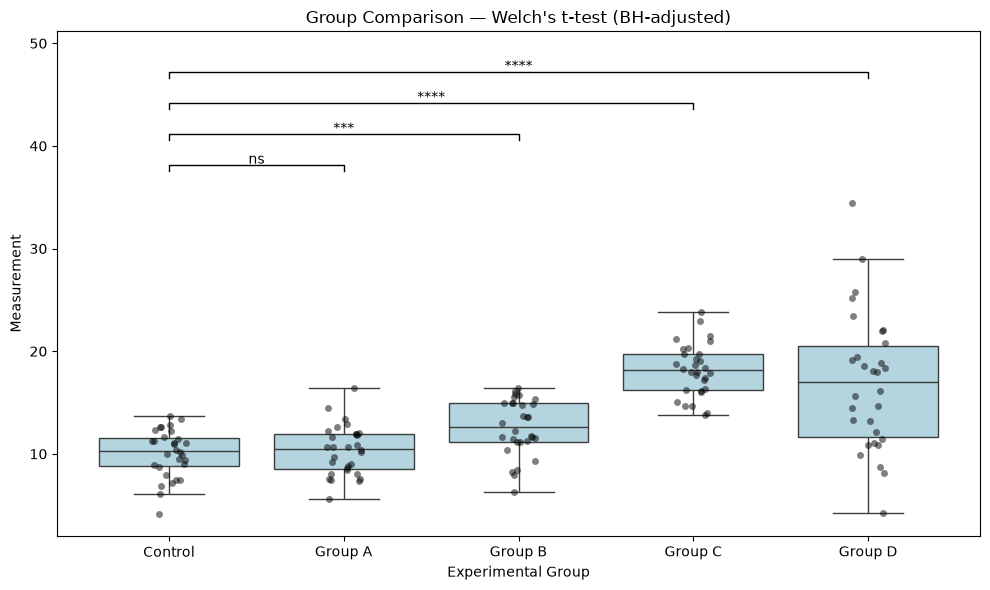

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(data=df, ax=ax, color="lightblue", showfliers=False)
sns.stripplot(data=df, ax=ax, color="black", alpha=0.5, jitter=True)

# Add BH-adjusted significance (Welch)
y_max = df.max().max()
spacing = (df.max().max() - df.min().min()) * 0.10

for i, row in results_df.iterrows():

    p = row["Welch adjusted p"]

    if p < 0.0001:
        label = "****"
    elif p < 0.001:
        label = "***"
    elif p < 0.01:
        label = "**"
    elif p < 0.05:
        label = "*"
    else:
        label = "ns"

    x1, x2 = 0, i + 1
    y = y_max + (i + 1) * spacing

    ax.plot([x1, x1, x2, x2],
            [y, y + spacing*0.2, y + spacing*0.2, y],
            color="black", linewidth=1)

    ax.text((x1 + x2)/2, y + spacing*0.25,
            label, ha="center")

ax.set_ylim(top=y_max + 5.5 * spacing)
ax.set_xlabel("Experimental Group")
ax.set_ylabel("Measurement")
ax.set_title("Group Comparison — Welch's t-test (BH-adjusted)")

plt.tight_layout()
plt.show()

## Confidence Intervals (95%)

**Purpose:** Estimate uncertainty in the population mean.

- **Mean:** Average measurement.
- **SEM:** Standard error of the mean (SD/√n).
- **95% CI:** Interval calculated using a method with 95% long-run coverage.

**Interpretation:** Narrower intervals indicate more precise estimates.

In [8]:
ci_results = []

for name in df.columns:
    data = df[name]

    mean = data.mean()
    sem = stats.sem(data)

    ci_low, ci_high = stats.t.interval(
        confidence=0.95,
        df=len(data)-1,
        loc=mean,
        scale=sem
    )

    ci_results.append({
        "Group": name,
        "Mean": mean,
        "CI Lower": ci_low,
        "CI Upper": ci_high
    })

ci_df = pd.DataFrame(ci_results)

display(ci_df.round(3))

,Group,Mean,CI Lower,CI Upper
0,Control,10.050,9.180,10.921
1,Group A,10.341,9.440,11.243
2,Group B,12.594,11.568,13.620
3,Group C,18.188,17.238,19.139
4,Group D,16.932,14.444,19.419


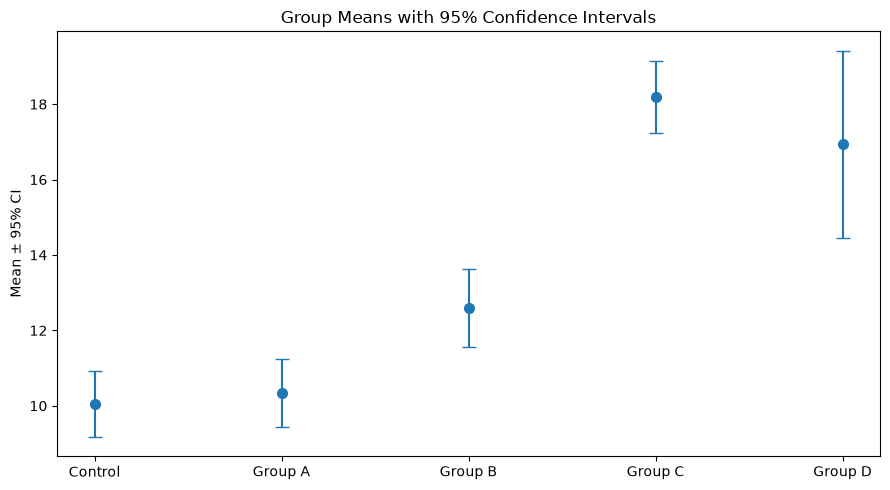

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))

means = ci_df["Mean"]

lower = means - ci_df["CI Lower"]
upper = ci_df["CI Upper"] - means

ax.errorbar(
    ci_df["Group"],
    means,
    yerr=[lower, upper],
    fmt="o",
    capsize=5,
    markersize=7
)

ax.set_ylabel("Mean ± 95% CI")
ax.set_title("Group Means with 95% Confidence Intervals")

plt.tight_layout()
plt.show()

## Bootstrap Analysis

**Purpose:** Estimate statistical uncertainty through resampling.

**Method:**
1. Randomly sample observations with replacement.
2. Calculate the mean.
3. Repeat 10,000 times.
4. Estimate a percentile-based 95% confidence interval.

**Interpretation:** The bootstrap distribution describes the variability of the estimated mean.

In [10]:
data = df["Control"].to_numpy()

rng_bootstrap = np.random.default_rng(123)
n_boot = 10000

bootstrap_means = np.empty(n_boot)

for i in range(n_boot):

    sample = rng_bootstrap.choice(
        data,
        size=len(data),
        replace=True
    )

    bootstrap_means[i] = np.mean(sample)

ci_lower, ci_upper = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

print(f"Original mean: {data.mean():.3f}")
print(f"Bootstrap 95% CI: [{ci_lower:.3f}, {ci_upper:.3f}]")

Original mean: 10.050
Bootstrap 95% CI: [9.209, 10.838]


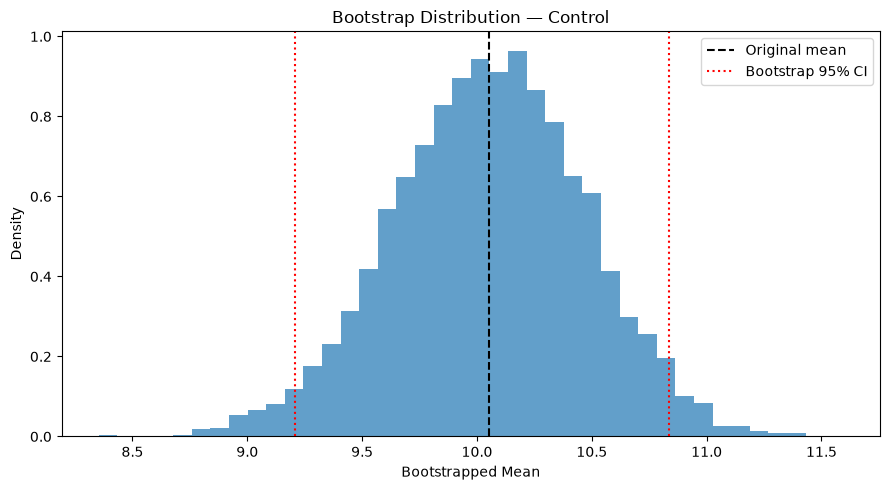

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    bootstrap_means,
    bins=40,
    density=True,
    alpha=0.7
)

ax.axvline(
    data.mean(),
    color="black",
    linestyle="--",
    label="Original mean"
)

ax.axvline(ci_lower, color="red", linestyle=":", label="Bootstrap 95% CI")
ax.axvline(ci_upper, color="red", linestyle=":")

ax.set_xlabel("Bootstrapped Mean")
ax.set_ylabel("Density")
ax.set_title("Bootstrap Distribution — Control")
ax.legend()

plt.tight_layout()
plt.show()

## Sensitivity Analysis — Sample Size

**Purpose:** Examine how sample size affects estimation precision.

**Parameter:** Number of observations (n).

**Fixed conditions:**
- Population mean = 10
- Population SD = 3

**Expected relationship:**
- SEM = SD / √n
- Larger n → Smaller uncertainty.

We repeat the simulation 1,000 times for each sample size to reduce random fluctuations.

In [12]:
rng_sensitivity = np.random.default_rng(123)

sample_sizes = [5, 10, 20, 30, 50, 100, 200, 500]
n_simulations = 1000

sensitivity_results = []

for n in sample_sizes:
    ci_widths = []

    for _ in range(n_simulations):
        sample = rng_sensitivity.normal(10, 3, n)

        sem = stats.sem(sample)

        ci = stats.t.interval(
            0.95,
            df=n-1,
            loc=np.mean(sample),
            scale=sem
        )

        ci_widths.append(ci[1] - ci[0])

    sensitivity_results.append({
        "N": n,
        "Mean CI Width": np.mean(ci_widths),
        "SD CI Width": np.std(ci_widths)
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(3))

,N,Mean CI Width,SD CI Width
0,5,7.039,2.550
1,10,4.163,1.013
2,20,2.778,0.461
3,30,2.225,0.295
4,50,1.692,0.171
5,100,1.188,0.085
6,200,0.835,0.041
7,500,0.526,0.017


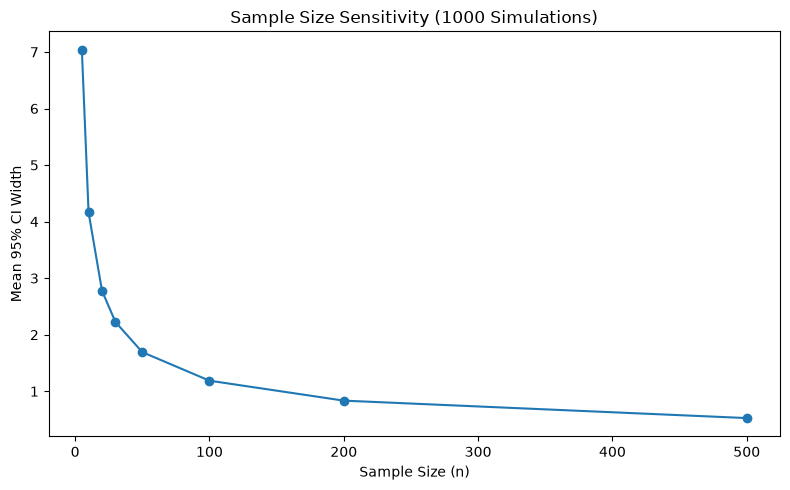

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    sensitivity_df["N"],
    sensitivity_df["Mean CI Width"],
    "o-"
)

plt.xlabel("Sample Size (n)")
plt.ylabel("Mean 95% CI Width")
plt.title("Sample Size Sensitivity (1000 Simulations)")

plt.tight_layout()
plt.show()